In [1]:
import h5py
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
import numpy as np
import json

import matplotlib.lines as mlines

In [2]:
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/cr_bowshock_outputs"
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

### Synchrotron luminosity per frequency vs time

ISM-v30
ISM-v30-HDiff
ISM-v30-LDiff
ISM-v100
ISM-v30-MHD


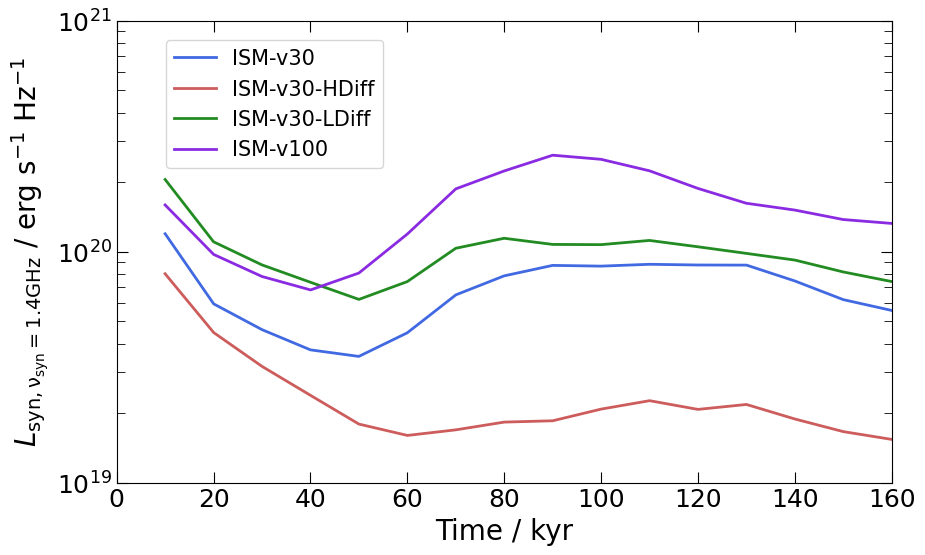

In [52]:
fig_tseries, ax_tseries = plt.subplots(figsize=(10, 6))

synch_freq = 1.4 * u.GHz  # choice of synchrotron frequency

for i, sim_name in enumerate(list(bowshock_config.keys())):
    print(sim_name)
    if sim_name == "ISM-v30-MHD" or sim_name == "ISM-v60":
        continue

    # write data to h5py file
    with h5py.File(f"{data_dir}/emission_data_synch.h5", "r") as pf:
        times = pf[sim_name]["times"][()]
        synch_freq_grid = pf[sim_name]["synch_freq"][()] * u.GHz

        synch_lum = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)

    synch_freq_idx = np.digitize(synch_freq, synch_freq_grid, right=True)
    synch_lum = synch_lum[:, synch_freq_idx]

    times = times[synch_lum > 0]
    synch_lum = synch_lum[synch_lum > 0]

    ax_tseries.semilogy(
        times, synch_lum, color=bowshock_config[sim_name]["color"], label=sim_name, lw=2.0
    )

ax_tseries.set_xlabel("Time / kyr", fontsize=20)
ax_tseries.set_ylabel(
    rf"$L_\mathrm{{syn, \nu_\mathrm{{syn}} = {synch_freq:.1f}}}$ / erg s$^{{-1}}$ Hz$^{{-1}}$", fontsize=20
)

# ylimits
ax_tseries.set_xlim(xmin=0, xmax=160)
ax_tseries.set_ylim(ymin=1e19, ymax=1e21)

# ticks
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="major",
    size=8,
    labelsize=18,
    right=True,
    top=True,
)
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="minor",
    size=6,
    labelsize=16,
    right=True,
    top=True,
)

ax_tseries.legend(prop={"size": 15}, loc="upper left", bbox_to_anchor=[0.05, 0.98])

# save
fig_tseries.savefig(
    f"{fig_dir}/synch/synch_lum_timeseries.pdf", bbox_inches="tight", dpi=300
)

### Time-averaged Synchrotron luminosity vs frequency 

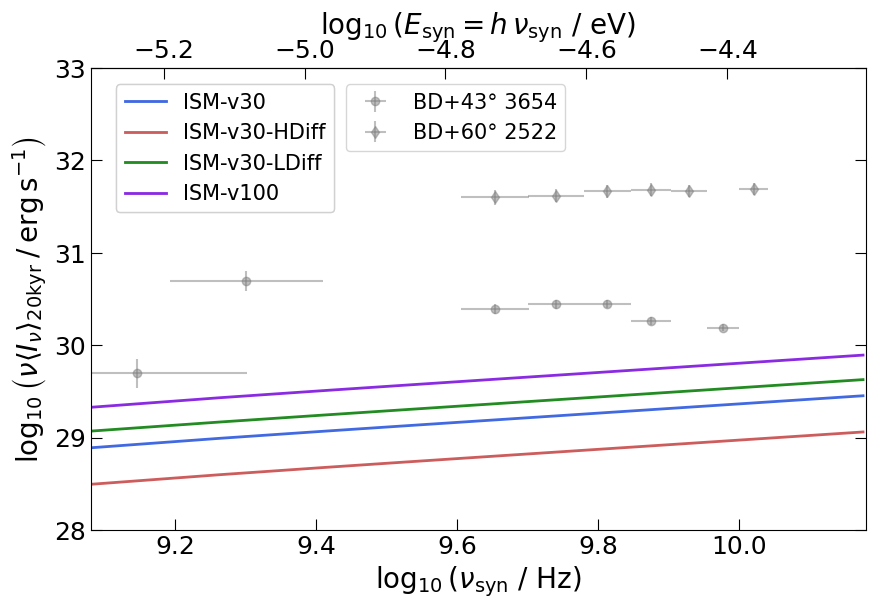

In [46]:
fig_tseries, ax_tseries = plt.subplots(figsize=(10, 6))

sim_handles = []
for i, sim_name in enumerate(list(bowshock_config.keys())):
    if sim_name == "ISM-v30-MHD" or sim_name == "ISM-v60":
        continue

    # read data from h5py file
    with h5py.File(f"{data_dir}/emission_data_synch.h5", "r") as pf:
        times = pf[sim_name]["times"][()] * u.kyr
        synch_lum = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)
        synch_freq_grid = pf[sim_name]["synch_freq"][()] * u.GHz

    # take the temporal average from 50 kyr or so
    tstart_idx = np.digitize(20 * u.kyr, times[:-1], right=True)
    synch_lum_tavg = np.mean(synch_lum[tstart_idx:], axis=0)

    ax_tseries.plot(
        np.log10(synch_freq_grid.to_value(u.Hz)),
        np.log10((synch_freq_grid.to(u.Hz) * synch_lum_tavg).to_value(u.erg / u.s)),
        color=bowshock_config[sim_name]["color"],
        label=sim_name,
        lw=2.0,
    )

    sim_handles.append(
        mlines.Line2D(
            [0],
            [0],
            lw=2.0,
            color=bowshock_config[sim_name]["color"],
            label=sim_name,
        )
    )

# plot data also
data_colors = ["gray", "gray"]
data_symbols = ["o", "d"]
data_labels = ["BD+43° 3654", "BD+60° 2522"]

data_handles = []
with h5py.File(f"{data_dir}/M22_data.h5", "r") as pf:
    for l, (bs_name, vd) in enumerate(list(pf.items())):
        synch_freq_data = vd["freq"][()] * u.GHz
        freq_err = 0.5 * u.GHz  # width of each sub-band
        d, d_err = vd["D"][()] * u.kpc
        flux = vd["flux"][()] * 1e-12 * (u.erg * u.s**-1 * u.cm**-2)
        # pure flux is 5% calibration uncertainty, but data is nu * flux so we have to include
        # frequency error for flux error calculation
        flux_err = flux * np.sqrt(0.05**2 + (freq_err / synch_freq_data) ** 2)

        # calcualte luminosity
        synch_lum_data = (4 * np.pi * d**2 * flux).to(u.erg * u.s**-1)
        synch_lum_data_err = (
            4 * np.pi * np.sqrt((2 * d * flux * d_err) ** 2 + (d**2 * flux_err) ** 2)
        ).to(u.erg * u.s**-1)

        log10_synch_lum_data = np.log10(synch_lum_data.value)
        log10_synch_lum_data_err = (
            synch_lum_data_err / (np.log(10) * synch_lum_data)
        ).value

        errorbar = ax_tseries.errorbar(
            np.log10(synch_freq_data.to_value(u.Hz)),
            log10_synch_lum_data,
            xerr=(freq_err / (np.log(10) * synch_freq_data)).value,
            yerr=log10_synch_lum_data_err,
            label=data_labels[l],
            marker=data_symbols[l],
            alpha=0.5,
            ls="",
            ms=6.0,
            color=data_colors[l],
        )

        data_handles.append(errorbar)

ax_tseries.set_xlabel(r"$\log_{10}(\nu_\mathrm{syn}$ / Hz)", fontsize=20)
ax_tseries.set_ylabel(
    r"$\log_{10}\left(\nu \langle L_\nu \rangle_\mathrm{20 kyr} \: / \: \mathrm{erg} \, \mathrm{s}^{-1} \right)$",
    fontsize=20,
)


# ylimits
ax_tseries.set_xlim(9.08, 10.18)
ax_tseries.set_ylim(ymin=28, ymax=33)

# ticks
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="major",
    size=8,
    labelsize=18,
    right=True,
)
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="minor",
    size=6,
    labelsize=16,
    right=True,
)

# generate twin axis for photon energy
secax = ax_tseries.secondary_xaxis(
    "top",
    functions=(
        lambda x: np.log10((10**x * u.Hz * const.h.si).to_value(u.eV)),
        lambda x: np.log10((10**x * u.eV / const.h.si).to_value(u.Hz)),
    ),
)
secax.set_xlabel(
    r"$\log_{10}(E_\mathrm{syn} = h\, \nu_\mathrm{syn}$ / $\mathrm{eV})$", fontsize=20
)
secax.tick_params(axis="x", which="major", labelsize=18, size=8, direction="in")
secax.tick_params(axis="x", which="minor", labelsize=18, size=6, direction="in")

# ax_tseries.legend(prop={"size": 14}, loc="upper left")
leg1 = fig_tseries.legend(
    handles=sim_handles,
    prop={"size": 15},
    loc="upper left",
    bbox_to_anchor=[0.14, 0.87],
)
fig_tseries.add_artist(leg1)
fig_tseries.legend(
    handles=data_handles,
    prop={"size": 15},
    loc="upper left",
    bbox_to_anchor=[0.37, 0.87],
)

fig_tseries.savefig(f"{fig_dir}/synch/synch_lum_freq.pdf", bbox_inches="tight", dpi=300)

## Gamma ray luminosity vs time

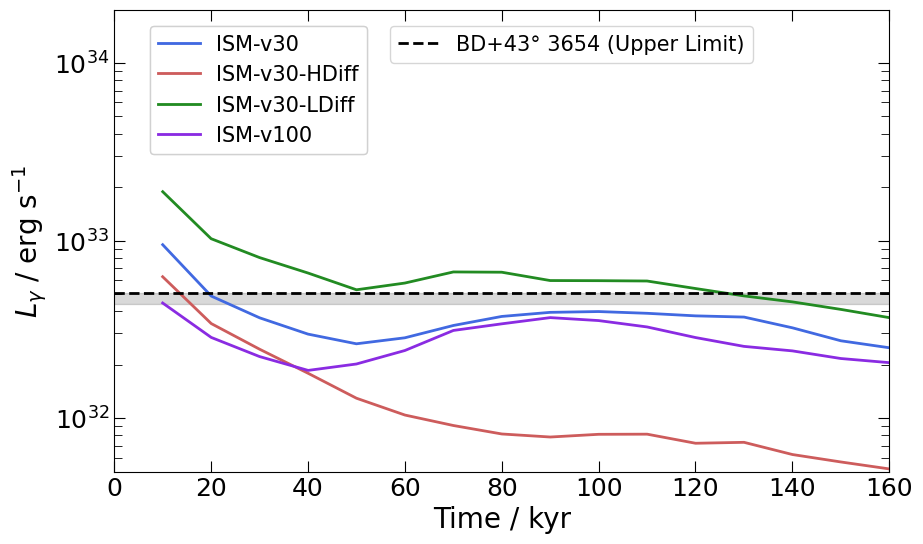

In [50]:
fig_tseries, ax_tseries = plt.subplots(figsize=(10, 6))

sim_handles=[]
for i, sim_name in enumerate(list(bowshock_config.keys())):
    # write data to h5py file
    with h5py.File(f"{data_dir}/emission_data_gamma.h5", "r") as pf:
        if sim_name not in list(pf.keys()):
            continue
        times = pf[sim_name]["times"][()]
        gamma_lum = pf[sim_name]["gamma_lum"][()] * u.erg * u.s**-1

    # remove outliers
    times = times[gamma_lum > 10 * u.erg * u.s**-1]
    gamma_lum = gamma_lum[gamma_lum > 10 * u.erg * u.s**-1]

    ax_tseries.semilogy(
        times[np.argsort(times)],
        gamma_lum[np.argsort(times)],
        color=bowshock_config[sim_name]["color"],
        label=sim_name,
        lw=2.0
    )
    sim_handles.append(
        mlines.Line2D(
            [0],
            [0],
            lw=2.0,
            color=bowshock_config[sim_name]["color"],
            label=sim_name,
        )
    )

# plot data also
data_handles=[]
with h5py.File(f"{data_dir}/S14_data.h5", "r") as pf:
    for l, (bs_name, vd) in enumerate(list(pf.items())):
        d, d_err = vd["D"][()] * u.kpc
        flux = vd["flux"][()] * 1e-12 * (u.erg * u.s**-1 * u.cm**-2)
        flux_err = 0.05 * flux  # 5% calibration uncertainty

        # calcualte luminosity
        gamma_lum_data = (4 * np.pi * d**2 * flux).to(u.erg * u.s**-1)
        gamma_lum_data_err = (
            4 * np.pi * np.sqrt((2 * d * flux * d_err) ** 2 + (d**2 * flux_err) ** 2)
        )

        mean_gamma_lum_data = np.mean(gamma_lum_data)
        mean_gamma_lum_data_err = np.sqrt(np.sum(gamma_lum_data_err**2))

        ax_tseries.axhline(
            mean_gamma_lum_data.value, color="k", ls="--", alpha=1.0, label="BD+43° 3654", lw=2.0
        )
        ax_tseries.fill_between(
            np.linspace(-20, 200, 100),
            # (mean_gamma_lum_data - mean_gamma_lum_data_err).value,
            (mean_gamma_lum_data - mean_gamma_lum_data_err).value,
            (mean_gamma_lum_data).value,
            color="k",
            alpha=0.15,
            zorder=0
        )

        data_handles.append(mlines.Line2D(
            [0],
            [0],
            lw=2.0,
            color="k",
            label="BD+43° 3654 (Upper Limit)",
            ls="--"
        ))


ax_tseries.set_xlabel("Time / kyr", fontsize=20)
ax_tseries.set_ylabel(r"$L_\gamma$ / erg s$^{-1}$", fontsize=20)

# limits
ax_tseries.set_xlim(xmin=0, xmax=160)
ax_tseries.set_ylim(ymin=5e31, ymax=2e34)

# ticks
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="major",
    size=8,
    labelsize=18,
    right=True,
    top=True,
)
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="minor",
    size=6,
    labelsize=16,
    right=True,
    top=True,
)

leg1 = fig_tseries.legend(
    handles=sim_handles,
    prop={"size": 15},
    loc="upper left",
    bbox_to_anchor=[0.15, 0.87]
)
fig_tseries.add_artist(leg1)
fig_tseries.legend(
    handles=data_handles,
    prop={"size": 15},
    loc="upper left",
    bbox_to_anchor=[0.39, 0.87],
)

# ax_tseries.legend(prop={"size": 15}, loc="upper left", bbox_to_anchor=[0.05, 0.98])

# save
fig_tseries.savefig(
    f"{fig_dir}/gamma/gamma_lum_timeseries.pdf", bbox_inches="tight", dpi=300
)